# NeuroPath AI — Fall Detection Model Training

**Model:** 1D-CNN binary classifier  
**Dataset:** SisFall Enhanced (pre-segmented binary files)  
**Output:** `../models/fall_detection_cnn.h5` — ready to load in the PyQt5 app

### Expected folder layout before running
```
neuropath/
├── notebooks/          ← this file lives here
│   └── 01_fall_detection_train.ipynb
├── models/             ← trained .h5 saved here automatically
└── data/
    └── sisfall/        ← paste the contents of your archive/ folder here
        ├── x_train_3
        ├── y_train_3
        ├── x_val_3
        ├── y_val_3
        ├── x_test_3
        ├── y_test_3
        └── weights_3.txt
```

> **Note:** Your downloaded `archive/` folder from Kaggle contains a subfolder called  
> `Three Classes/` — copy its contents into `data/sisfall/`.

## 1. Install / verify dependencies

In [17]:
# Run this cell once to make sure everything is installed.
# If you already have these, it will just print versions.
import subprocess, sys

required = ['tensorflow', 'scikit-learn', 'numpy', 'matplotlib', 'seaborn']
for pkg in required:
    try:
        __import__(pkg.replace('-','_'))
        print(f'  OK  {pkg}')
    except ImportError:
        print(f'  INSTALLING {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
        print(f'  DONE {pkg}')

  OK  tensorflow
  INSTALLING scikit-learn...
  DONE scikit-learn
  OK  numpy
  OK  matplotlib
  OK  seaborn


## 2. Imports

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, Flatten, Dense,
    Dropout, BatchNormalization, Input
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression

print(f'TensorFlow  : {tf.__version__}')
print(f'NumPy       : {np.__version__}')
print(f'GPU devices : {tf.config.list_physical_devices("GPU")}')
print(f'Running on  : {"GPU" if tf.config.list_physical_devices("GPU") else "CPU (no GPU found — training will be slower but works fine)"}')

TensorFlow  : 2.21.0
NumPy       : 1.26.4
GPU devices : []
Running on  : CPU (no GPU found — training will be slower but works fine)


## 3. Configure paths

Change `DATA_DIR` if you placed the SisFall files somewhere else.

In [19]:
# ── EDIT THIS IF YOUR FOLDER IS IN A DIFFERENT LOCATION ──────────────────────
DATA_DIR   = '../data/sisfall/'       # folder containing x_train_3, y_train_3 etc.
MODELS_DIR = '../models/'             # where the .h5 file will be saved
# ─────────────────────────────────────────────────────────────────────────────

os.makedirs(MODELS_DIR, exist_ok=True)

# Verify all required files exist
required_files = ['x_train_3','y_train_3','x_val_3','y_val_3','x_test_3','y_test_3','weights_3.txt']
missing = [f for f in required_files if not os.path.exists(os.path.join(DATA_DIR, f))]

if missing:
    print('❌ MISSING FILES — copy these into', DATA_DIR)
    for m in missing:
        print(f'   • {m}')
else:
    print('✅ All data files found in', os.path.abspath(DATA_DIR))

✅ All data files found in c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\data\sisfall


## 4. Load dataset

In [20]:
def load_binary(path, dtype):
    """Read a raw binary file into a NumPy array."""
    with open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=dtype)

# Labels (uint8)
y_train = load_binary(DATA_DIR + 'y_train_3', np.uint8)
y_val   = load_binary(DATA_DIR + 'y_val_3',   np.uint8)
y_test  = load_binary(DATA_DIR + 'y_test_3',  np.uint8)

# Features (float32) — each sample is 512 time steps
WINDOW_SIZE = 512
X_train = load_binary(DATA_DIR + 'x_train_3', np.float32).reshape(y_train.shape[0], WINDOW_SIZE)
X_val   = load_binary(DATA_DIR + 'x_val_3',   np.float32).reshape(y_val.shape[0],   WINDOW_SIZE)
X_test  = load_binary(DATA_DIR + 'x_test_3',  np.float32).reshape(y_test.shape[0],  WINDOW_SIZE)

# Class weights (for imbalanced data)
class_weights_arr = np.loadtxt(DATA_DIR + 'weights_3.txt')

print('Dataset loaded successfully')
print(f'  X_train : {X_train.shape}   y_train : {y_train.shape}')
print(f'  X_val   : {X_val.shape}   y_val   : {y_val.shape}')
print(f'  X_test  : {X_test.shape}   y_test  : {y_test.shape}')
print(f'  Class weights array: {class_weights_arr}')

# Class distribution
print('\nClass distribution (train):')
unique, counts = np.unique(y_train, return_counts=True)
labels = {0: 'Normal / ADL', 1: 'Fall'}
for u, c in zip(unique, counts):
    print(f'  Class {u} ({labels.get(u, "unknown")}): {c:,} samples ({c/len(y_train)*100:.1f}%)')

Dataset loaded successfully
  X_train : (233613, 512)   y_train : (233613,)
  X_val   : (60699, 512)   y_val   : (60699,)
  X_test  : (56652, 512)   y_test  : (56652,)
  Class weights array: [ 33.48391421 107.66810345   1.        ]

Class distribution (train):
  Class 0 (Normal / ADL): 155,742 samples (66.7%)
  Class 1 (Fall): 77,871 samples (33.3%)


## 5. Visualise example signals

Always sanity-check the raw data before training.

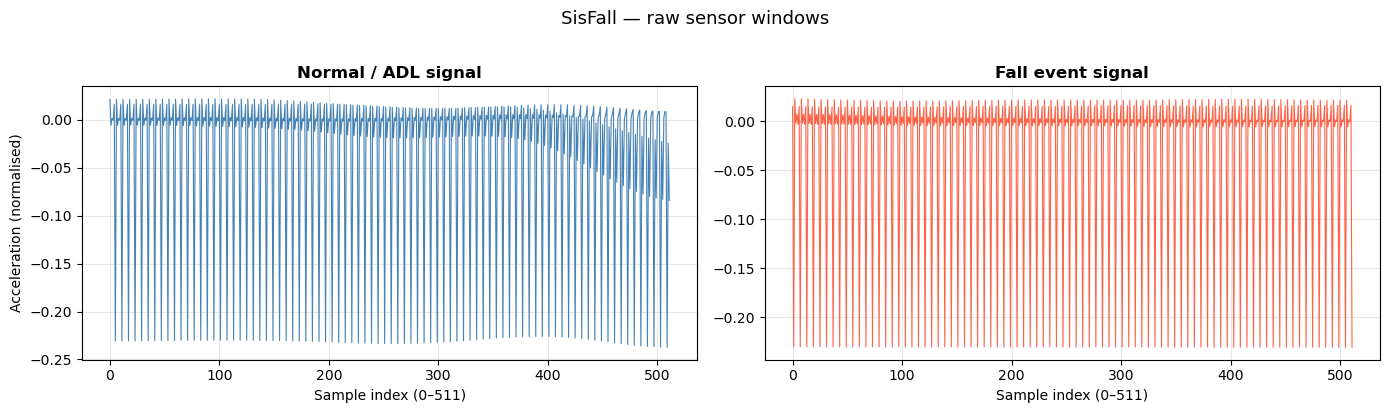

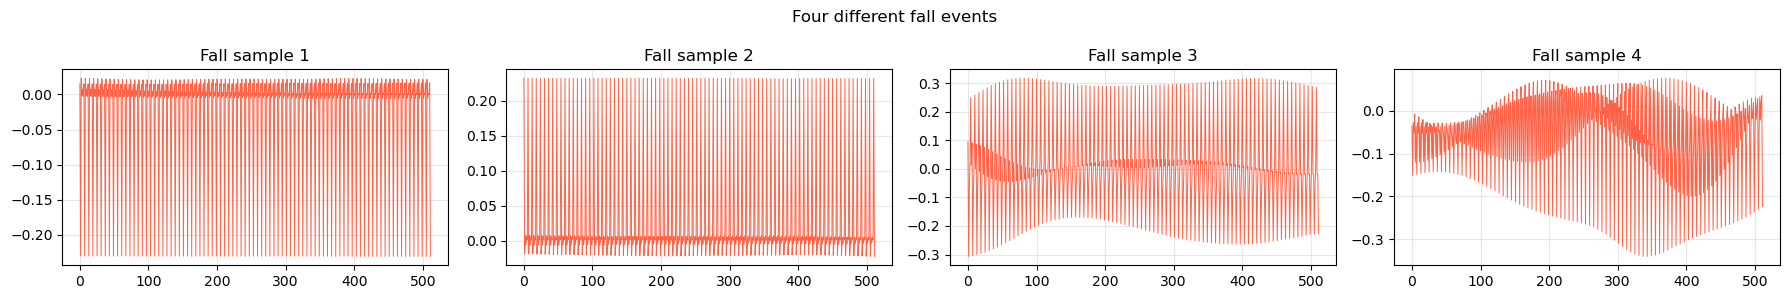

In [21]:
fall_idx    = np.where(y_train == 1)[0][0]
nonfal_idx  = np.where(y_train == 0)[0][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(X_train[nonfal_idx], color='steelblue', linewidth=0.8)
axes[0].set_title('Normal / ADL signal', fontweight='bold')
axes[0].set_xlabel('Sample index (0–511)')
axes[0].set_ylabel('Acceleration (normalised)')
axes[0].grid(alpha=0.3)

axes[1].plot(X_train[fall_idx], color='tomato', linewidth=0.8)
axes[1].set_title('Fall event signal', fontweight='bold')
axes[1].set_xlabel('Sample index (0–511)')
axes[1].grid(alpha=0.3)

plt.suptitle('SisFall — raw sensor windows', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

# Show multiple fall examples to understand variance
fall_indices = np.where(y_train == 1)[0][:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3))
for i, idx in enumerate(fall_indices):
    axes[i].plot(X_train[idx], color='tomato', linewidth=0.7)
    axes[i].set_title(f'Fall sample {i+1}')
    axes[i].grid(alpha=0.3)
plt.suptitle('Four different fall events', fontsize=12)
plt.tight_layout()
plt.show()

## 6. Build the 1D-CNN model

Architecture is identical to the original Kaggle notebook but with two improvements:
- Uses `Input()` layer explicitly (avoids the Keras deprecation warning)
- An extra Conv layer for better temporal feature extraction

In [22]:
# Reshape for CNN: (samples, timesteps, channels)
X_train_cnn = X_train.reshape(-1, WINDOW_SIZE, 1)
X_val_cnn   = X_val.reshape(-1, WINDOW_SIZE, 1)
X_test_cnn  = X_test.reshape(-1, WINDOW_SIZE, 1)

def build_fall_cnn(window_size=512):
    """
    Lightweight 1D-CNN for binary fall detection.
    Input  : (batch, 512, 1)  — single-channel accelerometer window
    Output : (batch, 1)       — sigmoid probability of fall
    """
    model = Sequential([
        Input(shape=(window_size, 1)),

        # Block 1 — detect low-level acceleration spikes
        Conv1D(32, kernel_size=5, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),          # 512 → 256

        # Block 2 — detect medium-range impact patterns
        Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),          # 256 → 128

        # Block 3 — higher-level temporal context
        Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),          # 128 → 64

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.4),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')     # probability of FALL
    ], name='fall_detection_cnn')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model = build_fall_cnn()
model.summary()

Model: "fall_detection_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 512, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 256, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 128, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089,025 (4.15 MB)

 Trainable params: 1,088,577 (4.15 MB)

 Non-trainable params: 448 (1.75 KB)

## 7. Train the model

**Expected time on CPU:** ~5–10 min per epoch (15 epochs max, early stopping usually kicks in around epoch 10–12)  
**Expected time on GPU:** ~1–2 min per epoch

The best weights are checkpointed automatically — if training crashes you can reload from `../models/fall_best_checkpoint.h5`.

In [23]:
# Class weight dict: index 0 = Normal, index 1 = Fall
# The weights_3.txt has 3 values (for the 3-class version); we use index 0 and 1
cw = {0: float(class_weights_arr[0]), 1: float(class_weights_arr[1])}
print(f'Class weights being used → Normal: {cw[0]:.2f}  |  Fall: {cw[1]:.2f}')
print('  (Higher weight on Fall means the model is penalised more for missing a fall)\n')

CHECKPOINT_PATH = MODELS_DIR + 'fall_best_checkpoint.h5'

callbacks = [
    EarlyStopping(
        monitor='val_auc',
        patience=5,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        patience=3,
        factor=0.5,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor='val_auc',
        save_best_only=True,
        mode='max',
        verbose=1
    )
]

history = model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=15,
    batch_size=512,
    class_weight=cw,
    callbacks=callbacks,
    verbose=1
)

print('\n✅ Training complete.')

Class weights being used → Normal: 33.48  |  Fall: 107.67
  (Higher weight on Fall means the model is penalised more for missing a fall)

Epoch 1/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9218 - auc: 0.9761 - loss: 10.5918
Epoch 1: val_auc improved from None to 0.97951, saving model to ../models/fall_best_checkpoint.h5



Epoch 1: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 183s 394ms/step - accuracy: 0.9462 - auc: 0.9878 - loss: 7.5767 - val_accuracy: 0.9176 - val_auc: 0.9795 - val_loss: 0.2032 - learning_rate: 0.0010
Epoch 2/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.9611 - auc: 0.9928 - loss: 5.3808
Epoch 2: val_auc improved from 0.97951 to 0.99466, saving model to ../models/fall_best_checkpoint.h5



Epoch 2: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 194s 425ms/step - accuracy: 0.9636 - auc: 0.9932 - loss: 5.1787 - val_accuracy: 0.9657 - val_auc: 0.9947 - val_loss: 0.0925 - learning_rate: 0.0010
Epoch 3/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.9692 - auc: 0.9946 - loss: 4.4040
Epoch 3: val_auc improved from 0.99466 to 0.99552, saving model to ../models/fall_best_checkpoint.h5



Epoch 3: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 220s 482ms/step - accuracy: 0.9693 - auc: 0.9946 - loss: 4.4376 - val_accuracy: 0.9687 - val_auc: 0.9955 - val_loss: 0.0944 - learning_rate: 0.0010
Epoch 4/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 584ms/step - accuracy: 0.9720 - auc: 0.9954 - loss: 4.0215
Epoch 4: val_auc improved from 0.99552 to 0.99623, saving model to ../models/fall_best_checkpoint.h5



Epoch 4: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 275s 602ms/step - accuracy: 0.9722 - auc: 0.9954 - loss: 4.0203 - val_accuracy: 0.9738 - val_auc: 0.9962 - val_loss: 0.0764 - learning_rate: 0.0010
Epoch 5/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.9733 - auc: 0.9957 - loss: 3.8450
Epoch 5: val_auc did not improve from 0.99623
457/457 ━━━━━━━━━━━━━━━━━━━━ 182s 399ms/step - accuracy: 0.9737 - auc: 0.9957 - loss: 3.8205 - val_accuracy: 0.9713 - val_auc: 0.9957 - val_loss: 0.0807 - learning_rate: 0.0010
Epoch 6/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step - accuracy: 0.9758 - auc: 0.9962 - loss: 3.5066
Epoch 6: val_auc did not improve from 0.99623
457/457 ━━━━━━━━━━━━━━━━━━━━ 151s 330ms/step - accuracy: 0.9758 - auc: 0.9962 - loss: 3.5126 - val_accuracy: 0.9735 - val_auc: 0.9962 - val_loss: 0.0765 - learning_rate: 0.0010
Epoch 7/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.9775 - auc: 0.9964 - loss: 3.3741
Ep


Epoch 7: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 152s 332ms/step - accuracy: 0.9774 - auc: 0.9965 - loss: 3.3359 - val_accuracy: 0.9752 - val_auc: 0.9965 - val_loss: 0.0697 - learning_rate: 0.0010
Epoch 8/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.9781 - auc: 0.9968 - loss: 3.1740
Epoch 8: val_auc did not improve from 0.99654
457/457 ━━━━━━━━━━━━━━━━━━━━ 148s 325ms/step - accuracy: 0.9780 - auc: 0.9967 - loss: 3.2023 - val_accuracy: 0.9752 - val_auc: 0.9965 - val_loss: 0.0716 - learning_rate: 0.0010
Epoch 9/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.9794 - auc: 0.9970 - loss: 2.9613
Epoch 9: val_auc improved from 0.99654 to 0.99656, saving model to ../models/fall_best_checkpoint.h5



Epoch 9: finished saving model to ../models/fall_best_checkpoint.h5
457/457 ━━━━━━━━━━━━━━━━━━━━ 136s 297ms/step - accuracy: 0.9789 - auc: 0.9970 - loss: 2.9828 - val_accuracy: 0.9775 - val_auc: 0.9966 - val_loss: 0.0642 - learning_rate: 0.0010
Epoch 10/15
457/457 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.9799 - auc: 0.9973 - loss: 2.7981
Epoch 10: val_auc did not improve from 0.99656
457/457 ━━━━━━━━━━━━━━━━━━━━ 147s 321ms/step - accuracy: 0.9795 - auc: 0.9971 - loss: 2.9038 - val_accuracy: 0.9761 - val_auc: 0.9965 - val_loss: 0.0709 - learning_rate: 0.0010
Epoch 11/15
 52/457 ━━━━━━━━━━━━━━━━━━━━ 2:23 353ms/step - accuracy: 0.9803 - auc: 0.9973 - loss: 2.6843

KeyboardInterrupt: 

## 8. Plot training curves

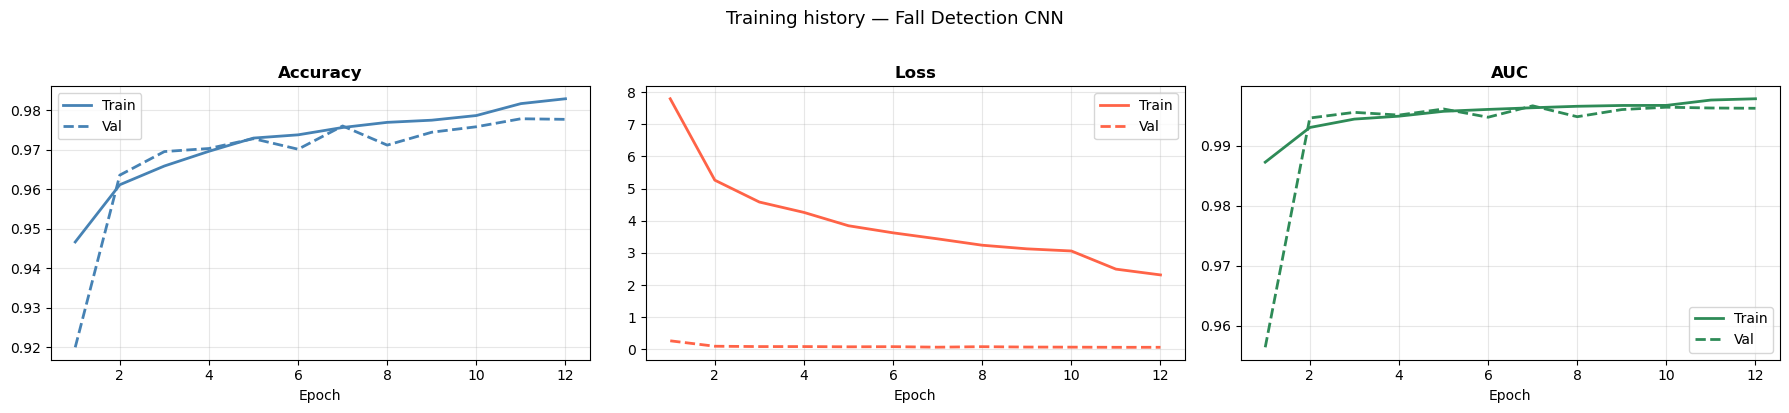

Saved training curves to ../models/fall_training_curves.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

metrics = [
    ('accuracy',     'val_accuracy',  'Accuracy',  'steelblue'),
    ('loss',         'val_loss',       'Loss',      'tomato'),
    ('auc',          'val_auc',        'AUC',       'seagreen'),
]

for ax, (train_key, val_key, title, color) in zip(axes, metrics):
    epochs_range = range(1, len(history.history[train_key]) + 1)
    ax.plot(epochs_range, history.history[train_key], label='Train', color=color, linewidth=2)
    ax.plot(epochs_range, history.history[val_key],   label='Val',   color=color, linewidth=2, linestyle='--')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Training history — Fall Detection CNN', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(MODELS_DIR + 'fall_training_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved training curves to', MODELS_DIR + 'fall_training_curves.png')

## 9. Evaluate on test set

In [ ]:
# Raw probability predictions
y_prob = model.predict(X_test_cnn, batch_size=512, verbose=0).flatten()

# Default threshold 0.5
y_pred = (y_prob >= 0.5).astype(int)

print('=' * 55)
print('CLASSIFICATION REPORT  (threshold = 0.50)')
print('=' * 55)
print(classification_report(
    y_test, y_pred,
    target_names=['Normal / ADL (0)', 'Fall (1)']
))

# AUC
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
print(f'ROC-AUC : {roc_auc:.4f}')

CLASSIFICATION REPORT  (threshold = 0.50)
                  precision    recall  f1-score   support

Normal / ADL (0)       0.99      0.97      0.98     37768
        Fall (1)       0.94      0.98      0.96     18884

        accuracy                           0.97     56652
       macro avg       0.97      0.98      0.97     56652
    weighted avg       0.97      0.97      0.97     56652

ROC-AUC : 0.9955


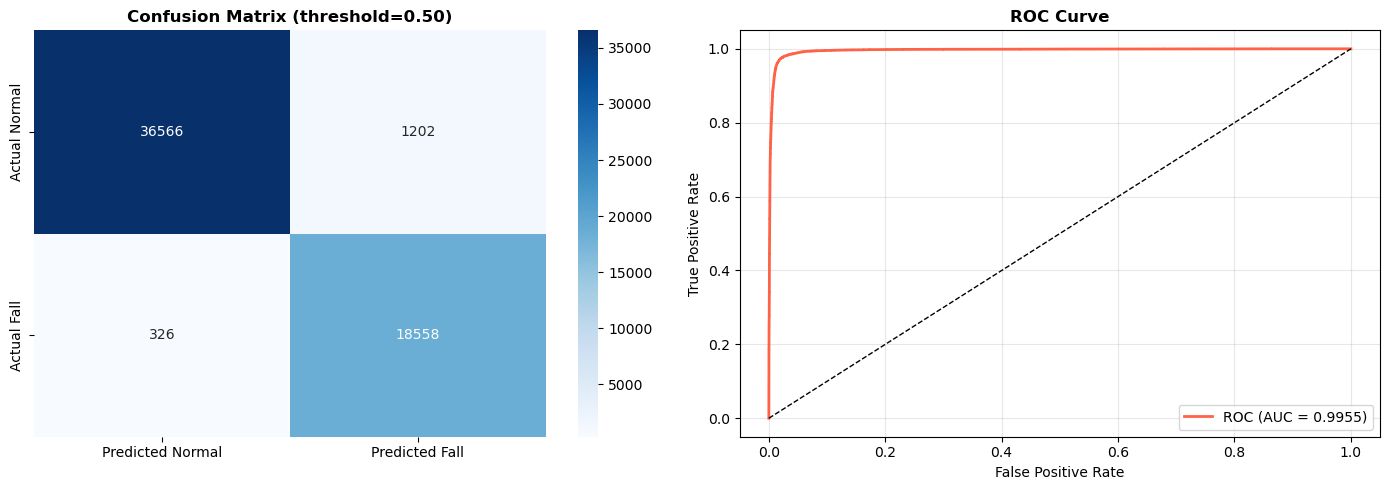

In [ ]:
# Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Predicted Normal', 'Predicted Fall'],
    yticklabels=['Actual Normal', 'Actual Fall']
)
axes[0].set_title('Confusion Matrix (threshold=0.50)', fontweight='bold')

# ROC curve
axes[1].plot(fpr, tpr, color='tomato', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODELS_DIR + 'fall_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Threshold tuning

For a **medical fall detector**, missing a real fall (false negative) is far more dangerous 
than a false alarm. We lower the threshold to ~0.3 so the model is more sensitive to falls.

In [ ]:
print('Threshold sweep — recall vs precision for the Fall class:\n')
print(f'{"Threshold":>12}  {"Fall Recall":>12}  {"Fall Prec":>10}  {"Fall F1":>8}  {"Accuracy":>10}')
print('-' * 60)

best_threshold = 0.5
best_f1 = 0.0

for thresh in np.arange(0.1, 0.9, 0.05):
    y_t = (y_prob >= thresh).astype(int)
    from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score
    rec  = recall_score(y_test, y_t, zero_division=0)
    prec = precision_score(y_test, y_t, zero_division=0)
    f1   = f1_score(y_test, y_t, zero_division=0)
    acc  = accuracy_score(y_test, y_t)
    marker = ' ← best F1' if f1 > best_f1 else ''
    print(f'{thresh:>12.2f}  {rec:>12.4f}  {prec:>10.4f}  {f1:>8.4f}  {acc:>10.4f}{marker}')
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = thresh

print(f'\n→ Recommended threshold: {best_threshold:.2f}')
print('  You can lower this further (e.g. 0.25) to prioritise catching every fall at the cost of more false alarms.')

Threshold sweep — recall vs precision for the Fall class:

   Threshold   Fall Recall   Fall Prec   Fall F1    Accuracy
------------------------------------------------------------
        0.10        0.9944      0.8623    0.9237      0.9452 ← best F1
        0.15        0.9932      0.8816    0.9341      0.9533 ← best F1
        0.20        0.9921      0.8938    0.9404      0.9581 ← best F1
        0.25        0.9904      0.9033    0.9449      0.9615 ← best F1
        0.30        0.9888      0.9109    0.9483      0.9640 ← best F1
        0.35        0.9874      0.9186    0.9518      0.9667 ← best F1
        0.40        0.9860      0.9257    0.9549      0.9690 ← best F1
        0.45        0.9847      0.9320    0.9576      0.9709 ← best F1
        0.50        0.9827      0.9392    0.9605      0.9730 ← best F1
        0.55        0.9801      0.9476    0.9636      0.9753 ← best F1
        0.60        0.9770      0.9540    0.9654      0.9766 ← best F1
        0.65        0.9736      0.9603

## 11. Save the final model

This cell saves three things the PyQt5 app needs:
- `fall_detection_cnn.h5` — the trained Keras model
- `fall_model_config.json` — threshold + window size metadata
- `fall_evaluation.png` — evaluation chart (for display in the app)

In [ ]:
# ── Save Keras model ──────────────────────────────────────────────────────────
MODEL_SAVE_PATH = MODELS_DIR + 'fall_detection_cnn.h5'
model.save(MODEL_SAVE_PATH)
print(f'✅ Model saved → {os.path.abspath(MODEL_SAVE_PATH)}')

# ── Save config JSON (loaded by the app at runtime) ───────────────────────────
config = {
    'model_file'       : 'fall_detection_cnn.h5',
    'window_size'      : int(WINDOW_SIZE),
    'input_shape'      : [int(WINDOW_SIZE), 1],
    'threshold'        : round(float(best_threshold), 2),
    'classes'          : {"0": "Normal", "1": "Fall"},
    'sampling_rate_hz' : 50,
    'window_seconds'   : round(WINDOW_SIZE / 50, 2),
    'val_auc'          : round(float(max(history.history['val_auc'])), 4),
    'roc_auc_test'     : round(float(roc_auc), 4),
    'description'      : '1D-CNN binary classifier trained on SisFall Enhanced dataset'
}

CONFIG_PATH = MODELS_DIR + 'fall_model_config.json'
with open(CONFIG_PATH, 'w') as f:
    json.dump(config, f, indent=2)
print(f'✅ Config saved → {os.path.abspath(CONFIG_PATH)}')

print('\nConfig contents:')
for k, v in config.items():
    print(f'  {k:20s}: {v}')

✅ Model saved → c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\models\fall_detection_cnn.h5
✅ Config saved → c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\models\fall_model_config.json

Config contents:
  model_file          : fall_detection_cnn.h5
  window_size         : 512
  input_shape         : [512, 1]
  threshold           : 0.65
  classes             : {'0': 'Normal', '1': 'Fall'}
  sampling_rate_hz    : 50
  window_seconds      : 10.24
  val_auc             : 0.9967
  roc_auc_test        : 0.9955
  description         : 1D-CNN binary classifier trained on SisFall Enhanced dataset


## 12. Quick inference test

Simulates exactly what the PyQt5 app will do when it receives a live sensor window.

In [ ]:
import json
from tensorflow.keras.models import load_model

# Load model + config fresh (simulates what the app does at startup)
loaded_model  = load_model(MODEL_SAVE_PATH)
with open(CONFIG_PATH) as f:
    loaded_cfg = json.load(f)

THRESHOLD = loaded_cfg['threshold']
WIN       = loaded_cfg['window_size']

def predict_window(raw_window: np.ndarray) -> dict:
    """
    Takes a 1D NumPy array of shape (512,) — one sensor window —
    and returns a prediction dict.

    This is the EXACT function signature used in the PyQt5 app.
    """
    assert raw_window.shape == (WIN,), f'Expected shape ({WIN},), got {raw_window.shape}'
    x = raw_window.reshape(1, WIN, 1).astype(np.float32)
    prob = float(loaded_model.predict(x, verbose=0)[0][0])
    label = 'FALL' if prob >= THRESHOLD else 'NORMAL'
    return {'label': label, 'confidence': round(prob, 4), 'threshold': THRESHOLD}

# Test on 3 real samples from test set
test_indices = [
    np.where(y_test == 0)[0][0],   # a real Normal sample
    np.where(y_test == 0)[0][1],   # another Normal
    np.where(y_test == 1)[0][0],   # a real Fall sample
]

print(f'Inference test  (threshold = {THRESHOLD})')
print('-' * 50)
for idx in test_indices:
    result = predict_window(X_test[idx])
    actual = 'FALL' if y_test[idx] == 1 else 'NORMAL'
    match  = '✅' if result['label'] == actual else '❌'
    print(f'  {match}  Actual: {actual:6s}  →  Predicted: {result["label"]:6s}  (conf: {result["confidence"]:.4f})')

print('\n✅ Model ready for integration into the NeuroPath app.')
print(f'   Load it with: load_model("{MODEL_SAVE_PATH}")')

Inference test  (threshold = 0.65)
--------------------------------------------------
  ✅  Actual: NORMAL  →  Predicted: NORMAL  (conf: 0.0000)
  ✅  Actual: NORMAL  →  Predicted: NORMAL  (conf: 0.0000)
  ✅  Actual: FALL    →  Predicted: FALL    (conf: 0.9911)

✅ Model ready for integration into the NeuroPath app.
   Load it with: load_model("../models/fall_detection_cnn.h5")


## 13. Baseline comparison (Logistic Regression)

Always train a simple baseline to confirm the CNN is actually better.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

print('Training Logistic Regression baseline...')
lr = LogisticRegression(max_iter=1000, n_jobs=-1)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print('\nLogistic Regression:')
print(classification_report(y_test, lr_pred, target_names=['Normal', 'Fall']))

cnn_acc = float(max(history.history['val_accuracy']))
lr_acc  = accuracy_score(y_test, lr_pred)

print(f'Summary:')
print(f'  Logistic Regression accuracy : {lr_acc:.4f}')
print(f'  CNN best val accuracy        : {cnn_acc:.4f}')
print(f'  CNN improvement              : +{(cnn_acc - lr_acc)*100:.2f}%')

Training Logistic Regression baseline...

Logistic Regression:
              precision    recall  f1-score   support

      Normal       0.89      0.97      0.93     37768
        Fall       0.93      0.75      0.83     18884

    accuracy                           0.90     56652
   macro avg       0.91      0.86      0.88     56652
weighted avg       0.90      0.90      0.90     56652

Summary:
  Logistic Regression accuracy : 0.8997
  CNN best val accuracy        : 0.9778
  CNN improvement              : +7.81%


---
## ✅ Done — what was produced

| File | Purpose |
|------|--------|
| `models/fall_detection_cnn.h5` | Trained Keras model — loaded by the app |
| `models/fall_model_config.json` | Threshold, window size, AUC scores |
| `models/fall_training_curves.png` | Training history chart |
| `models/fall_evaluation.png` | ROC curve + confusion matrix |
| `models/fall_best_checkpoint.h5` | Best epoch weights (backup) |

**Next step:** Run notebook `02_tremor_classifier_train.ipynb` using `imu-hand-tremor-parkinsons.csv`.